# Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("../data_cleaning/panel_weekly.csv")

print(df.shape)
print(df.head())
print(df.info())
df.columns

(4365, 11)
         week    commodity       ret    mom_4w   mom_12w   vol_12w    target  \
0  2010-01-01    crude_oil  0.016784  0.056464  0.112384  0.045818  0.042717   
1  2010-01-01         gold -0.008061 -0.064041  0.047588  0.024435  0.039262   
2  2010-01-01       copper  0.017273  0.036664  0.168475  0.030087  0.018182   
3  2010-01-01  natural_gas -0.012582  0.209087  0.197335  0.087556  0.031766   
4  2010-01-01        wheat  0.032412  0.010031  0.163318  0.054906  0.049861   

   net_tone  n_relevant  has_news  attention  
0       0.0         0.0         0        0.0  
1       0.0         0.0         0        0.0  
2       0.0         0.0         0        0.0  
3       0.0         0.0         0        0.0  
4       0.0         0.0         0        0.0  
<class 'pandas.DataFrame'>
RangeIndex: 4365 entries, 0 to 4364
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   week        4365 non-null   str    
 1   co

Index(['week', 'commodity', 'ret', 'mom_4w', 'mom_12w', 'vol_12w', 'target',
       'net_tone', 'n_relevant', 'has_news', 'attention'],
      dtype='str')

In [2]:
# 1. Vérifier les valeurs manquantes
print("Valeurs manquantes :")
print(df.isnull().sum())

# 2. Vérifier les doublons
print("\nDoublons :", df.duplicated().sum())

# 3. Vérifier qu'il n'existe qu'une observation
# par matière première et par semaine
print(
    "\nDoublons week + commodity :",
    df.duplicated(subset=["week", "commodity"]).sum()
)

# 4. Statistiques descriptives
print("\nStatistiques descriptives :")
display(df.describe())

# 5. Vérifier les périodes couvertes
print("\nPremière semaine :", df["week"].min())
print("Dernière semaine :", df["week"].max())

Valeurs manquantes :
week          0
commodity     0
ret           0
mom_4w        0
mom_12w       0
vol_12w       0
target        0
net_tone      0
n_relevant    0
has_news      0
attention     0
dtype: int64

Doublons : 0

Doublons week + commodity : 0

Statistiques descriptives :


,ret,mom_4w,mom_12w,vol_12w,target,net_tone,n_relevant,has_news,attention
count,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000
mean,0.001686,0.006809,0.020141,0.042286,0.001674,0.018959,2.862772,0.536999,0.752098
std,0.050091,0.096042,0.158501,0.027660,0.050126,0.458186,11.220693,0.498686,0.884284
min,-0.293098,-0.763677,-1.022311,0.007624,-0.293098,-1.000000,0.000000,0.000000,0.000000
25%,-0.022130,-0.040647,-0.058624,0.024308,-0.022136,0.000000,0.000000,0.000000,0.000000
50%,0.001166,0.004922,0.016250,0.035090,0.001160,0.000000,1.000000,1.000000,0.693147
75%,0.023610,0.053251,0.094552,0.051270,0.023610,0.166667,3.000000,1.000000,1.386294
max,0.699968,0.737780,0.955557,0.249565,0.699968,1.000000,401.000000,1.000000,5.996452



Première semaine : 2010-01-01
Dernière semaine : 2026-09-18


In [3]:
# Conversion des dates
df["week"] = pd.to_datetime(df["week"])

# Rendements extrêmes (> 30 % ou < -30 %)
extreme_returns = df[
    (df["ret"].abs() > 0.30) |
    (df["target"].abs() > 0.30)
]

print("Nombre de rendements extrêmes :",
      len(extreme_returns))

display(
    extreme_returns[
        ["week", "commodity", "ret", "target"]
    ].sort_values("week")
)

# Semaines ayant plus de 100 articles pertinents
extreme_news = df[df["n_relevant"] > 100]

print("\nObservations avec plus de 100 articles :",
      len(extreme_news))

display(
    extreme_news[
        ["week", "commodity", "n_relevant", "net_tone"]
    ].sort_values("n_relevant", ascending=False)
)

Nombre de rendements extrêmes : 10


,week,commodity,ret,target
2670,2020-03-27,crude_oil,-0.041016,0.317527
2675,2020-04-03,crude_oil,0.317527,-0.196895
3174,2022-02-25,wheat,0.057716,0.599051
3179,2022-03-04,wheat,0.599051,-0.191395
3738,2024-04-26,natural_gas,-0.078767,0.327138
3743,2024-05-03,natural_gas,0.327138,0.051354
4188,2026-01-16,natural_gas,-0.020827,0.699968
4193,2026-01-23,natural_gas,0.699968,-0.174597
4215,2026-02-27,crude_oil,0.009489,0.356312
4220,2026-03-06,crude_oil,0.356312,0.085919



Observations avec plus de 100 articles : 12


,week,commodity,n_relevant,net_tone
4225,2026-03-13,crude_oil,401.0,0.590524
4220,2026-03-06,crude_oil,220.0,0.793636
4265,2026-05-08,crude_oil,191.0,-0.249215
4295,2026-06-19,crude_oil,184.0,-0.616848
4230,2026-03-20,crude_oil,160.0,0.565625
4320,2026-07-24,crude_oil,159.0,0.594969
4310,2026-07-10,crude_oil,132.0,0.328030
4315,2026-07-17,crude_oil,127.0,0.638583
4270,2026-05-15,crude_oil,121.0,0.468595
4260,2026-05-01,crude_oil,118.0,0.486441


In [4]:
# Vérification de la couverture des actualités

df["week"] = pd.to_datetime(df["week"])
df["year"] = df["week"].dt.year

coverage = df.groupby(
    ["year", "commodity"]
).agg(
    weeks=("week", "nunique"),
    weeks_with_news=("has_news", "sum"),
    total_articles=("n_relevant", "sum"),
    max_articles=("n_relevant", "max")
).reset_index()

# Pourcentage de semaines avec actualités
coverage["coverage_pct"] = (
    100 * coverage["weeks_with_news"]
    / coverage["weeks"]
).round(2)

# Tableau de comparaison entre années
coverage_table = coverage.pivot(
    index="year",
    columns="commodity",
    values="coverage_pct"
)

display(coverage_table)

commodity,copper,crude_oil,gold,natural_gas,wheat
year,,,,,
2010,32.08,32.08,86.79,3.77,1.89
2011,48.08,46.15,86.54,15.38,7.69
2012,42.31,32.69,80.77,5.77,0.00
2013,38.46,34.62,88.46,9.62,0.00
2014,26.92,38.46,86.54,3.85,0.00
2015,36.54,65.38,82.69,13.46,1.92
2016,39.62,60.38,98.11,9.43,1.89
2017,78.85,67.31,100.00,7.69,11.54
2018,59.62,96.15,98.08,94.23,50.00


In [5]:


# 1. Convertir les dates
df["week"] = pd.to_datetime(df["week"])

# 2. Trier les données chronologiquement
df = df.sort_values(["week", "commodity"]).copy()

# 3. Date correspondant au rendement à prédire
df["target_week"] = df["week"] + pd.Timedelta(days=7)

print(df.head())

# 4. Séparation chronologique
train = df[df["target_week"] < "2021-01-01"].copy()

val = df[
    (df["week"] >= "2021-01-01") &
    (df["target_week"] < "2024-01-01")
].copy()

test = df[df["week"] >= "2024-01-01"].copy()

# 5. Afficher les résultats
print("Train :", train.shape)
print("Validation :", val.shape)
print("Test :", test.shape)

print("\nPériode Train :", train["week"].min(), train["week"].max())
print("Période Validation :", val["week"].min(), val["week"].max())
print("Période Test :", test["week"].min(), test["week"].max())

        week    commodity       ret    mom_4w   mom_12w   vol_12w    target  \
2 2010-01-01       copper  0.017273  0.036664  0.168475  0.030087  0.018182   
0 2010-01-01    crude_oil  0.016784  0.056464  0.112384  0.045818  0.042717   
1 2010-01-01         gold -0.008061 -0.064041  0.047588  0.024435  0.039262   
3 2010-01-01  natural_gas -0.012582  0.209087  0.197335  0.087556  0.031766   
4 2010-01-01        wheat  0.032412  0.010031  0.163318  0.054906  0.049861   

   net_tone  n_relevant  has_news  attention  year target_week  
2       0.0         0.0         0        0.0  2010  2010-01-08  
0       0.0         0.0         0        0.0  2010  2010-01-08  
1       0.0         0.0         0        0.0  2010  2010-01-08  
3       0.0         0.0         0        0.0  2010  2010-01-08  
4       0.0         0.0         0        0.0  2010  2010-01-08  
Train : (2865, 13)
Validation : (780, 13)
Test : (710, 13)

Période Train : 2010-01-01 00:00:00 2020-12-18 00:00:00
Période Validation 

# Modèles par matière première

Un modèle est estimé **séparément pour chaque matière première**. Pour chaque
couple (modèle, jeu de variables), les prévisions sont rassemblées dans une
matrice `semaines × matières premières` : un vecteur de rendements prévus par
matière première. Cette matrice est l'entrée de l'étape portefeuille.

Deux jeux de variables sont comparés, à modèle et fenêtre identiques :

| Jeu | Variables |
|---|---|
| A : prix | `ret`, `mom_4w`, `mom_12w`, `vol_12w` |
| B : prix + news | les mêmes + `net_tone`, `n_relevant`, `has_news`, `attention` |

## Configuration

In [6]:

PRICE = ["ret", "mom_4w", "mom_12w", "vol_12w"]
NEWS = ["net_tone", "n_relevant", "has_news", "attention"]

FEATURE_SETS = {
    "A: price": PRICE,
    "B: price+news": PRICE + NEWS,
}

COMS = sorted(df["commodity"].unique())
TARGET = "target"

print("Matières premières :", COMS)
print("Jeux de variables  :", list(FEATURE_SETS))

Matières premières : ['copper', 'crude_oil', 'gold', 'natural_gas', 'wheat']
Jeux de variables  : ['A: price', 'B: price+news']


## Modèles

`RidgeCV` choisit la pénalité par validation croisée temporelle sur le train
uniquement. Les arbres sont volontairement contraints : chaque modèle n'est
estimé que sur les observations d'une seule matière première.

In [7]:
def make_models(seed=42):
    return {
        "Ridge": RidgeCV(
            alphas=np.logspace(-2, 5, 40),
            cv=TimeSeriesSplit(5)
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=3,
            min_samples_leaf=30,
            random_state=seed,
            n_jobs=-1
        ),
        "LightGBM": LGBMRegressor(
            n_estimators=150,
            learning_rate=0.02,
            max_depth=3,
            num_leaves=5,
            min_child_samples=30,
            reg_lambda=5.0,
            random_state=seed,
            n_jobs=-1,
            verbosity=-1
        ),
    }

print("Modèles :", list(make_models()))

Modèles : ['Ridge', 'Random Forest', 'LightGBM']


## Métriques

`R2_oos` est calculé par rapport à la moyenne du train **de la matière première
concernée** (convention de Campbell-Thompson), et non par rapport à la moyenne
de l'échantillon de validation. `IC_t` est la statistique de Student de l'IC :
avec environ 156 semaines, un IC doit dépasser 0,16 en valeur absolue pour
sortir du bruit.

In [8]:
def evaluate(y_true, y_pred, benchmark):
    #benchmark : the mean of that commodity’s training returns
    y = np.asarray(y_true)
    p = np.asarray(y_pred)
    n = len(y)

    ic = np.corrcoef(y, p)[0, 1] if np.std(p) > 1e-12 else 0.0
    ic_t = ic * np.sqrt(n - 2) / np.sqrt(max(1 - ic ** 2, 1e-12))

    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "R2_oos": 1 - ((y - p) ** 2).sum() / ((y - benchmark) ** 2).sum(),
        "DirAcc": np.mean((y > 0) == (p > 0)),
        "IC": ic,
        "IC_t": ic_t,
        "n": n,
    }

## Estimation : une boucle par matière première

Pour chaque matière première, chaque jeu de variables et chaque modèle :
estimation sur le train, prévision sur la validation, et stockage de la
prévision dans la colonne correspondante de la matrice `ALPHA`.

In [9]:
# Rendements réalisés : semaines x matières premières
RET = (val.pivot(index="week", columns="commodity", values=TARGET)
          .sort_index()) #passer une table du format long au format large

#print(type(RET),RET.head())

# Une matrice de prévisions par (modèle, jeu de variables)
ALPHA = {
    (mdl_name, fs_name): pd.DataFrame(index=RET.index, columns=COMS, dtype=float)
    for fs_name in FEATURE_SETS # Models A and B (price and price + news)
    for mdl_name in make_models() # ML models (ridge, random forest, lightbtm)
}

rows = [] # Predictions from the baseline
ridge_alphas = []

# For each commodity : COMS =[all commodities]
for com in COMS:

    tr = train[train["commodity"] == com]
    va = val[val["commodity"] == com].sort_values("week") 

    y_tr = tr[TARGET]
    y_va = va[TARGET]

    # Baseline : moyenne du train de cette matière première
    benchmark = np.full(len(y_va), y_tr.mean())

    m = evaluate(y_va, benchmark, benchmark) # Function coded give the dictionary (metric:error)
    m.update(commodity=com, model="Baseline", features="—") # add this in m : "commodity": com, "model": model, "features": "e.g B: price+news"
    rows.append(m)

    for fs_name, feats in FEATURE_SETS.items():
        for mdl_name, mdl in make_models().items():

            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("model", mdl)
            ]).fit(tr[feats], y_tr)

            y_pred = pipe.predict(va[feats])

            # Vecteur de rendements prévus pour cette matière première
            ALPHA[(mdl_name, fs_name)].loc[va["week"].values, com] = y_pred

            m = evaluate(y_va, y_pred, benchmark)
            m.update(commodity=com, model=mdl_name, features=fs_name)
            rows.append(m)

            if mdl_name == "Ridge":
                ridge_alphas.append({
                    "commodity": com,
                    "features": fs_name,
                    "alpha": pipe.named_steps["model"].alpha_
                })

results = (pd.DataFrame(rows)
             .set_index(["commodity", "model", "features"])
             [["MAE", "RMSE", "R2_oos", "DirAcc", "IC", "IC_t", "n"]])

print("Modèles estimés :", len(COMS) * len(FEATURE_SETS) * len(make_models()))

Modèles estimés : 30


## Performances, matière première par matière première

In [10]:
display(results.round(4))

MAE    RMSE  R2_oos  DirAcc  \
commodity   model         features                                        
copper      Baseline      —              0.0261  0.0340  0.0000  0.5321   
            Ridge         A: price       0.0260  0.0339  0.0012  0.5641   
            Random Forest A: price       0.0264  0.0342 -0.0126  0.4808   
            LightGBM      A: price       0.0269  0.0347 -0.0463  0.4744   
            Ridge         B: price+news  0.0260  0.0339  0.0008  0.5449   
            Random Forest B: price+news  0.0264  0.0341 -0.0114  0.4872   
            LightGBM      B: price+news  0.0268  0.0348 -0.0480  0.5256   
crude_oil   Baseline      —              0.0399  0.0536  0.0000  0.5577   
            Ridge         A: price       0.0398  0.0545 -0.0353  0.5833   
            Random Forest A: price       0.0403  0.0552 -0.0602  0.5192   
            LightGBM      A: price       0.0405  0.0556 -0.0782  0.5385   
            Ridge         B: price+news  0.0403  0.0546 -0.0371  0.5192   
            Random Forest B: price+news  0.0404  0.0552 -0.0624  0.5321   
            LightGBM      B: price+news  0.0406  0.0559 -0.0868  0.5064   
gold        Baseline      —              0.0146  0.0191  0.0000  0.5513   
            Ridge         A: price       0.0146  0.0191  0.0001  0.5513   
            Random Forest A: price       0.0145  0.0191  0.0073  0.5449   
            LightGBM      A: price       0.0145  0.0191 -0.0011  0.5064   
            Ridge         B: price+news  0.0146  0.0191  0.0002  0.5513   
            Random Forest B: price+news  0.0145  0.0190  0.0148  0.5449   
            LightGBM      B: price+news  0.0144  0.0190  0.0091  0.5705   
natural_gas Baseline      —              0.0699  0.0891  0.0000  0.5000   
            Ridge         A: price       0.0700  0.0893 -0.0051  0.4679   
            Random Forest A: price       0.0713  0.0908 -0.0398  0.4679   
            LightGBM      A: price       0.0721  0.0921 -0.0682  0.4808   
            Ridge         B: price+news  0.0701  0.0892 -0.0035  0.5000   
            Random Forest B: price+news  0.0713  0.0908 -0.0388  0.4808   
            LightGBM      B: price+news  0.0721  0.0921 -0.0685  0.4808   
wheat       Baseline      —              0.0408  0.0679  0.0000  0.4872   
            Ridge         A: price       0.0406  0.0684 -0.0153  0.5449   
            Random Forest A: price       0.0405  0.0680 -0.0032  0.5833   
            LightGBM      A: price       0.0404  0.0683 -0.0125  0.6090   
            Ridge         B: price+news  0.0406  0.0679 -0.0000  0.5256   
            Random Forest B: price+news  0.0405  0.0680 -0.0033  0.5769   
            LightGBM      B: price+news  0.0404  0.0683 -0.0125  0.6090   

                                             IC    IC_t    n  
commodity   model         features                            
copper      Baseline      —              0.0000  0.0000  156  
            Ridge         A: price       0.0377  0.4687  156  
            Random Forest A: price       0.0100  0.1236  156  
            LightGBM      A: price      -0.0062 -0.0776  156  
            Ridge         B: price+news  0.0423  0.5259  156  
            Random Forest B: price+news  0.0117  0.1451  156  
            LightGBM      B: price+news -0.0018 -0.0225  156  
crude_oil   Baseline      —              0.0000  0.0000  156  
            Ridge         A: price      -0.0705 -0.8774  156  
            Random Forest A: price      -0.0648 -0.8053  156  
            LightGBM      A: price      -0.0550 -0.6836  156  
            Ridge         B: price+news -0.0570 -0.7086  156  
            Random Forest B: price+news -0.0667 -0.8294  156  
            LightGBM      B: price+news -0.0598 -0.7437  156  
gold        Baseline      —              0.0000  0.0000  156  
            Ridge         A: price       0.0973  1.2131  156  
            Random Forest A: price       0.0876  1.0914  156  
            LightGBM      A: price       0.0718  0.8927  156  
        

α contrôle la force du rétrécissement des coefficients. RidgeCV le choisit dans np.logspace(-2, 5, 40), donc entre 0,01 et 100 000.

α petit : la CV estime que les variables apportent de l’information, les coefficients restent grands, les prévisions varient.
α = 100 000 (le haut de la grille) : la CV a écrasé tous les coefficients. Le modèle prédit essentiellement la constante. Il n’a trouvé aucune relation stable sur le train.

In [11]:
# Pénalité Ridge retenue par validation croisée.
# Une valeur en haut de la grille signifie que le modèle est
# ramené vers la moyenne : aucun signal exploitable.

display(
    pd.DataFrame(ridge_alphas)
      .pivot(index="commodity", columns="features", values="alpha")
)

features,A: price,B: price+news
commodity,,
copper,2424.462017,5541.020330
crude_oil,203.091762,307.029063
gold,100000.000000,100000.000000
natural_gas,1060.818355,2424.462017
wheat,203.091762,1603.718744


## Information coefficient

Seule métrique qui sépare réellement les modèles : MAE et RMSE sont dominées
par la variance non prévisible des rendements hebdomadaires.

IC is the strength, and specifically the linear strength. It’s a correlation, so it only sees co-movement that’s proportional. If the model were right about direction but systematically wrong about magnitude, IC would still be high — correlation is scale-free. And if the relationship were genuinely non-linear, IC could be near zero while the forecast still contained information.
IC measures how strong my predictions is correlated to the real value and t how sure.

In [12]:
ic_table = (results.reset_index()
                   .query("model != 'Baseline'")
                   .pivot_table(index="commodity",
                                columns=["model", "features"],
                                values="IC"))

SE = 2 / np.sqrt(results["n"].max())

print(f"Bande de bruit : |IC| < {SE:.3f}  (2 écarts-types)")
display(ic_table.round(3))

Bande de bruit : |IC| < 0.160  (2 écarts-types)


model       LightGBM               Random Forest                  Ridge  \
features    A: price B: price+news      A: price B: price+news A: price   
commodity                                                                 
copper        -0.006        -0.002         0.010         0.012    0.038   
crude_oil     -0.055        -0.060        -0.065        -0.067   -0.071   
gold           0.072         0.110         0.088         0.128    0.097   
natural_gas   -0.105        -0.112        -0.127        -0.123   -0.025   
wheat          0.021         0.021         0.044         0.044   -0.034   

model                      
features    B: price+news  
commodity                  
copper              0.042  
crude_oil          -0.057  
gold                0.055  
natural_gas        -0.044  
wheat               0.009

In [13]:
# Apport des news, à modèle et fenêtre identiques

gain = (ic_table.xs("B: price+news", level=1, axis=1)
        - ic_table.xs("A: price", level=1, axis=1))

display(gain.round(3).style.background_gradient(axis=None, cmap="RdYlGn"))

model,LightGBM,Random Forest,Ridge
commodity,,,
copper,0.004000,0.002000,0.005000
crude_oil,-0.005000,-0.002000,0.014000
gold,0.038000,0.040000,-0.042000
natural_gas,-0.007000,0.005000,-0.019000
wheat,0.000000,-0.001000,0.044000


## Vecteurs de rendements prévus

Pour chaque couple (modèle, jeu de variables), une matrice
`semaines × matières premières`. `RET` contient les rendements réalisés sur la
même grille, ce qui permet d'écrire directement `pnl = (h * RET).sum(axis=1)`
à l'étape portefeuille.

In [14]:
A = ALPHA[("Ridge", "B: price+news")]

print("Dimensions :", A.shape)
print("Valeurs manquantes :", int(A.isna().sum().sum()))
display(A.head())

# Dispersion des prévisions : une colonne quasi constante
# produira des positions dégénérées à l'étape portefeuille.
display(A.std().rename("écart-type des prévisions").to_frame().T.round(5))

Dimensions : (156, 5)
Valeurs manquantes : 0


,copper,crude_oil,gold,natural_gas,wheat
week,,,,,
2021-01-01,0.000447,-0.001247,0.001216,0.001210,-0.000083
2021-01-08,0.000182,0.003196,0.001181,0.000926,0.000441
2021-01-15,0.000463,0.003119,0.001229,0.000115,-0.000161
2021-01-22,0.000211,-0.007479,0.001223,0.001515,0.000180
2021-01-29,0.000381,-0.007261,0.001213,0.001613,0.000478


,copper,crude_oil,gold,natural_gas,wheat
écart-type des prévisions,0.00034,0.00685,0.00002,0.00253,0.00166


## Graphiques

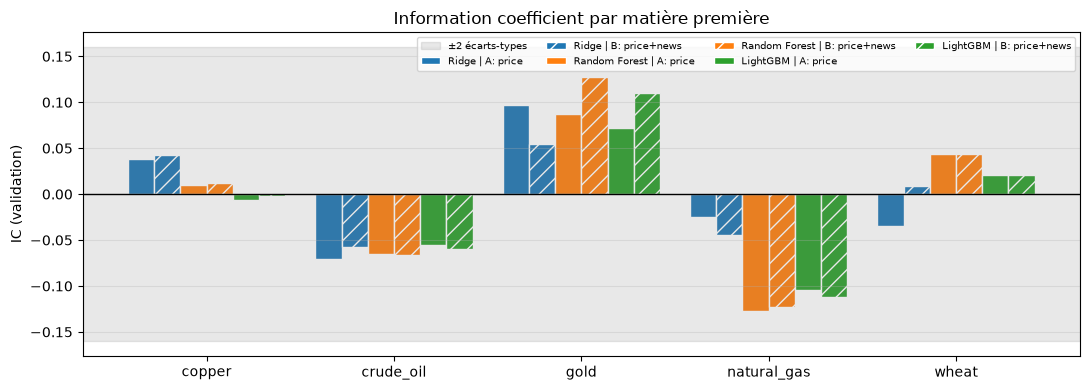

In [15]:
COLORS = {"Ridge": "C0", "Random Forest": "C1", "LightGBM": "C2"}
HATCH = {"A: price": "", "B: price+news": "//"}

fig, ax = plt.subplots(figsize=(11, 4))

x = np.arange(len(COMS))
width = 0.14

for i, (mdl_name, fs_name) in enumerate(
        [(m, f) for m in COLORS for f in HATCH]):

    values = [results.loc[(c, mdl_name, fs_name), "IC"] for c in COMS]

    ax.bar(x + (i - 2.5) * width, values, width,
           color=COLORS[mdl_name], hatch=HATCH[fs_name],
           edgecolor="white", label=f"{mdl_name} | {fs_name}")

ax.axhline(0, color="k", lw=1)
ax.axhspan(-SE, SE, color="grey", alpha=0.18, label="±2 écarts-types")
ax.set_xticks(x)
ax.set_xticklabels(COMS)
ax.set_ylabel("IC (validation)")
ax.set_title("Information coefficient par matière première")
ax.legend(fontsize=7, ncol=4)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## PnL de diagnostic

Le PnL ci-dessous **n'est pas un backtest** : c'est un diagnostic visuel du
signal, matière première par matière première. La position suit une règle ad hoc
— signe de la prévision, taille proportionnelle à son amplitude (plafonnée à 3×) —
et le PnL est le cumul de `position × rendement réalisé` durant toute la validation, brut de coûts.

$$\text{pos}_t = \text{sign}(\hat r_t)\;\min\!\left(\frac{|\hat r_t|}{\overline{|\hat r|}},\,3\right)$$

Ni covariance, ni contraintes, ni coûts, ni positions précédentes. Le portefeuille
transversal avec optimisation dynamique vient à l'étape 7 ; cette courbe lui
servira de référence naïve.

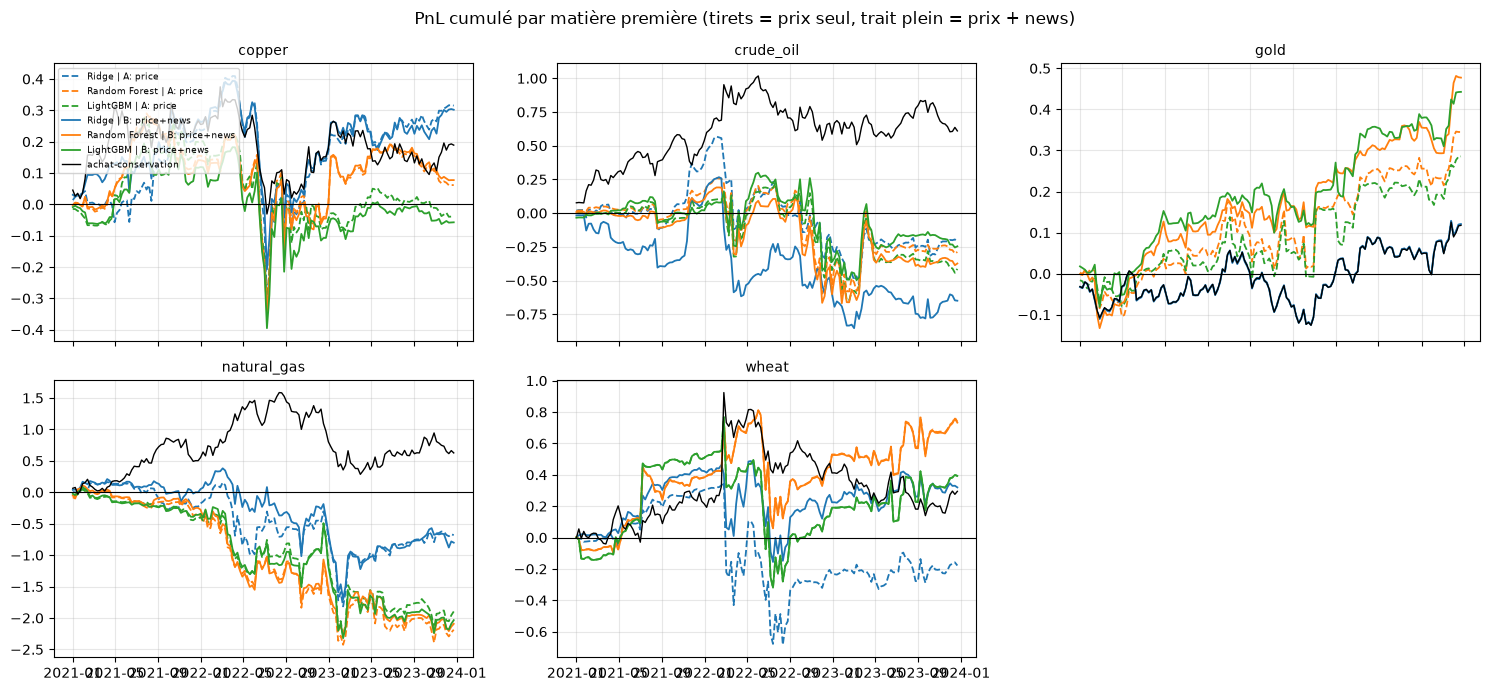

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)

for ax, com in zip(axes.ravel(), COMS):

    for (mdl_name, fs_name), A in ALPHA.items():

        # Position = signe de la prévision, taille proportionnelle
        # à son amplitude (plafonnée)
        pos = np.sign(A[com]) * (A[com].abs() / A[com].abs().mean()).clip(0, 3)

        ax.plot(RET.index, (pos * RET[com]).cumsum(),
                color=COLORS[mdl_name],
                ls="--" if fs_name == "A: price" else "-",
                lw=1.3, label=f"{mdl_name} | {fs_name}")

    ax.plot(RET.index, RET[com].cumsum(), color="k", lw=1, label="achat-conservation")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(com, fontsize=10)
    ax.grid(alpha=0.3)

axes.ravel()[-1].axis("off")
axes.ravel()[0].legend(fontsize=6.5, loc="upper left")

fig.suptitle("PnL cumulé par matière première "
             "(tirets = prix seul, trait plein = prix + news)")
fig.tight_layout()
plt.show()

## Lecture

- Les prévisions sont beaucoup moins volatiles que les rendements : c'est
  normal. Pour un IC de $\rho$, la prévision optimale a un écart-type de
  $\rho\,\sigma(r)$.
- $R^2_{oos} \approx 2\rho k - k^2$ avec $k = \sigma(\hat r)/\sigma(r)$ :
  une prévision qui varie sans corréler avec les rendements perd
  mécaniquement contre la baseline.
- Le PnL ci-dessus est brut de coûts et calculé matière première par matière
  première. Le portefeuille de l'étape 7 est transversal et intègre les coûts
  de transaction et les positions précédentes.

# COmputation of the portfolio : Dynamic optimization (Transaction cost)  

Les prévisions `ALPHA` sont converties en positions par l'optimisation
moyenne-variance avec coûts quadratiques du chapitre 30 du cours.

Sans coût, chaque date est résolue isolément :

$$h_t = \lambda V_t^{-1}\alpha_t$$

Avec un coût quadratique de facteur $\Lambda$, le problème devient dynamique —
les positions précédentes entrent dans la solution :

$$h_t = \left[\frac{V_t}{\lambda} + \Lambda_t\right]^{-1}(\alpha_t + \Lambda_t h_{t-1})$$

soit, de façon équivalente,

$$h_t = (I + \lambda V^{-1}\Lambda)^{-1}\lambda V^{-1}\alpha_t
      + \left[I - (I + \lambda V^{-1}\Lambda)^{-1}\right] h_{t-1}$$

Le portefeuille optimal est une moyenne pondérée de la cible sans friction et
des positions passées : faute de pouvoir atteindre la cible gratuitement, on ne
s'en rapproche que partiellement.

## Fonctions utilisées

Tout vient de `skfin`, rien n'est réimplémenté ici :

| Import | Rôle |
|---|---|
| `skfin.backtesting.Backtester` | backtest walk-forward sans coût |
| `skfin.estimators.MeanVariance` | optimiseur moyenne-variance |
| `skfin.backtesting_with_cost.MeanVarianceWithCost` | optimiseur avec coût quadratique |
| `skfin.backtesting_with_cost.BacktesterWithCost` | backtest qui transmet `h_{t-1}` à chaque pas |
| `skfin.backtesting_with_cost.compute_pnl_components` | décomposition brut / coût / net |
| `skfin.backtesting_with_cost.average_holding_period` | durée de détention moyenne |
| `skfin.metrics.sharpe_ratio` | ratio de Sharpe annualisé |
| `skfin.plot.line`, `skfin.plot.bar` | graphiques du cours |

Le module `skfin/backtesting_with_cost.py` est créé par la cellule `%%writefile`
du notebook `30_Transaction_cost.ipynb`. Si l'import échoue, exécuter cette
cellule une fois.

In [17]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from skfin.backtesting import Backtester
from skfin.estimators import MeanVariance
from skfin.metrics import sharpe_ratio
from skfin.plot import line, bar

from skfin.backtesting_with_cost import (
    BacktesterWithCost,
    MeanVarianceWithCost,
    average_holding_period,
    compute_pnl_components,
)

## Matrices passées au backtester

Le `Backtester` du cours attend trois objets de même forme
`semaines × actifs` :

| Objet | Contenu | Rôle |
|---|---|---|
| `features` | les prévisions `ALPHA` | entrée de l'optimiseur |
| `target` | rendement de t+1 aligné sur la semaine de décision t | estimation de $V$ |
| `ret` | rendement réalisé de la semaine t | calcul du pnl |

Le pnl s'écrit `h.shift(1) * ret` : la position prise en t−1 gagne le rendement
de la semaine t. C'est le `pred_lag=1` du cours.

Une difficulté : `ALPHA` ne couvre que la validation, alors que le backtester a
besoin d'une fenêtre d'historique pour estimer $V$. On construit donc
`ALPHA_FULL` sur tout l'échantillon — les prévisions d'avant 2021 sont
in-sample et ne servent qu'à amorcer les fenêtres ; les positions ne commencent
qu'au 1er janvier 2021, fixé par `start_date`.

In [18]:
# Prévisions sur tout l'échantillon (amorçage des fenêtres du backtester).
# Les modèles restent estimés sur le train uniquement.

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

ALPHA_FULL = {}

for fs_name, feats in FEATURE_SETS.items():
    for mdl_name in make_models():
        ALPHA_FULL[(mdl_name, fs_name)] = pd.DataFrame(
            index=sorted(df["week"].unique()), columns=COMS, dtype=float
        )

for com in COMS:

    tr = train[train["commodity"] == com]
    full = df[df["commodity"] == com].sort_values("week")

    for fs_name, feats in FEATURE_SETS.items():
        for mdl_name, mdl in make_models().items():

            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("model", mdl)
            ]).fit(tr[feats], tr[TARGET])

            ALPHA_FULL[(mdl_name, fs_name)].loc[full["week"].values, com] = (
                pipe.predict(full[feats])
            )

print(ALPHA_FULL.keys())
print("Dimensions avant dropna ALPHA_FULL :", ALPHA_FULL[("Ridge", "B: price+news")].shape)


ALPHA_FULL = {k: v.dropna() for k, v in ALPHA_FULL.items()}

print("Dimensions ALPHA_FULL :", ALPHA_FULL[("Ridge", "B: price+news")].shape)

dict_keys([('Ridge', 'A: price'), ('Random Forest', 'A: price'), ('LightGBM', 'A: price'), ('Ridge', 'B: price+news'), ('Random Forest', 'B: price+news'), ('LightGBM', 'B: price+news')])
Dimensions avant dropna ALPHA_FULL : (873, 5)
Dimensions ALPHA_FULL : (873, 5)


In [32]:
# target : rendement de t+1 aligné sur la semaine de décision t (estimation de V)
TARGET_FULL = df.pivot(index="week", columns="commodity", values="target").sort_index()

# ret : rendement réalisé de la semaine t (calcul du pnl)
RET_REAL = df.pivot(index="week", columns="commodity", values="ret").sort_index()

START, END = "2021-01-01", "2023-12-31"

print("TARGET_FULL :", TARGET_FULL.shape, " RET_REAL :", RET_REAL.shape)

TARGET_FULL : (873, 5)  RET_REAL : (873, 5)


## Facteur coût-liquidité

Le cours construit
$\Lambda_{n,t} = \frac{\gamma}{2}\cdot\frac{\sigma_{n,t}}{\text{poids de liquidité}_n}$,
avec $\gamma = 1/2000$ (on échange gamma du volume quotidien). Faute de
données de volume sur les contrats à terme, les poids de liquidité sont pris
égaux : les matières premières ne se distinguent alors que par leur volatilité.

`GAMMA` doit être calibré. La cellule suivante affiche le rapport
coût cumulé / pnl brut : un coût qui représente 10 à 40 % du pnl brut est
plausible ; un rapport de plusieurs dizaines signifie que `GAMMA` est trop
grand et que l'optimiseur se contentera de ne rien faire.

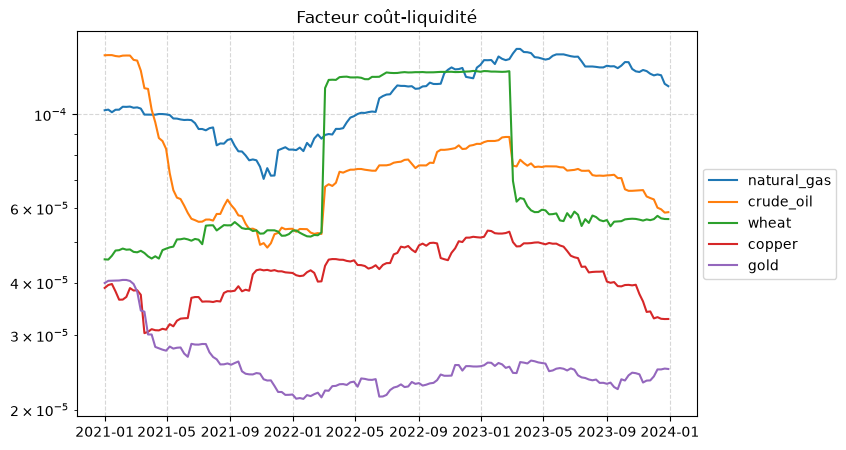

In [33]:
GAMMA = 1 / 2000
LIQ_W = pd.Series(1 / len(COMS), index=COMS)

vol_liquidity_factor = (
    0.5 * GAMMA * RET_REAL.rolling(52).std().div(LIQ_W, axis=1)
).loc[:, COMS]

line(vol_liquidity_factor.loc[START:END], yscale="log",
     title="Facteur coût-liquidité")

In [34]:
# Calibration de GAMMA : coût cumulé rapporté au pnl brut
models =['Ridge', 'Random Forest', 'LightGBM']

# models[0]: Ridge, models[1]: Random Forest, models[2] : LightGBM, pour prédiction et donc portefeuil
KEY = (models[0], "B: price+news")

m_probe = BacktesterWithCost(
    MeanVarianceWithCost(),
    vol_liquidity_factor=None,
    max_train_size=52,
    test_size=1,
    start_date=START,
    end_date=END,
).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)

for g in [1/20, 1/200, 1/2000, 1/20000]:
    vlf = (0.5 * g * RET_REAL.rolling(52).std().div(LIQ_W, axis=1)).loc[:, COMS]
    p = compute_pnl_components(m_probe.h_, RET_REAL, vol_liquidity_factor=vlf)
    ratio = -p["impact cost"].sum() / abs(p["gross"].sum())
    print(f"gamma = 1/{int(1/g):<6}  coût / brut = {ratio:8.2f}")

gamma = 1/20      coût / brut =    17.93
gamma = 1/200     coût / brut =     1.79
gamma = 1/2000    coût / brut =     0.18
gamma = 1/20000   coût / brut =     0.02


## Référence : moyenne-variance sans coût

`BacktesterWithCost` avec `vol_liquidity_factor=None` redonne exactement le
backtest `MeanVariance` du cours. Le coût est ensuite appliqué *après coup* aux
positions, pour mesurer ce qu'une stratégie qui ignore le coût paierait
réellement.

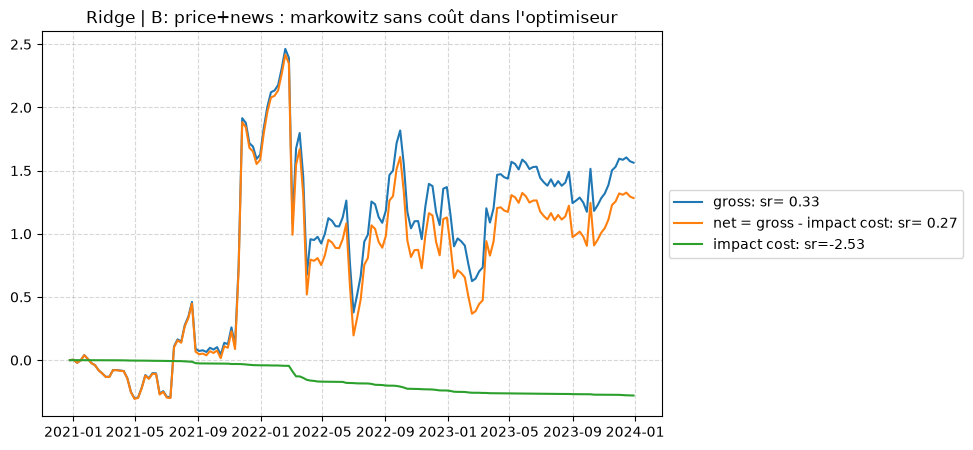

In [35]:


BT_KW = dict(max_train_size=52, test_size=1, start_date=START, end_date=END)

m0 = BacktesterWithCost(
    MeanVarianceWithCost(), vol_liquidity_factor=None, **BT_KW
).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)

pnlc = compute_pnl_components(
    m0.h_, RET_REAL, vol_liquidity_factor=vol_liquidity_factor
)

line(pnlc, cumsum=True,
     title=f"{KEY[0]} | {KEY[1]} : markowitz sans coût dans l'optimiseur")

## Optimisation dynamique avec coût quadratique

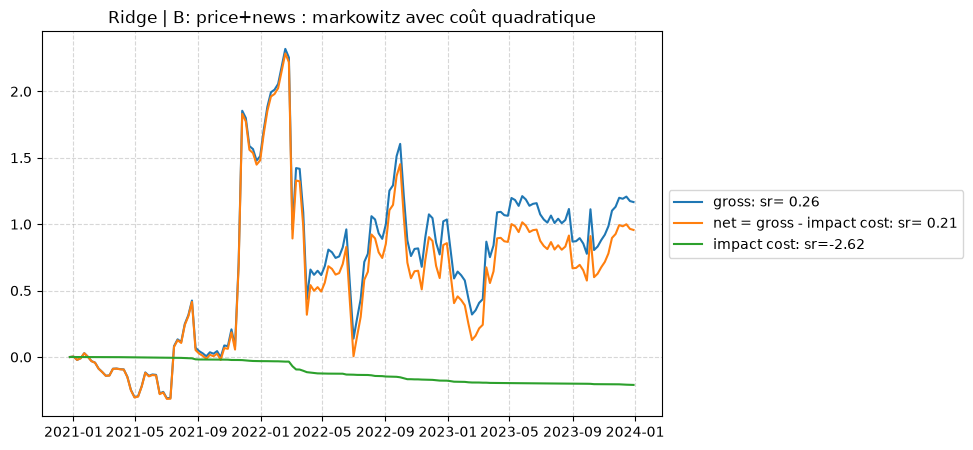

In [36]:
m = BacktesterWithCost(
    MeanVarianceWithCost(),
    vol_liquidity_factor,
    return_pnl_component=True,
    **BT_KW,
).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)

line(m.pnl_, cumsum=True,
     title=f"{KEY[0]} | {KEY[1]} : markowitz avec coût quadratique")

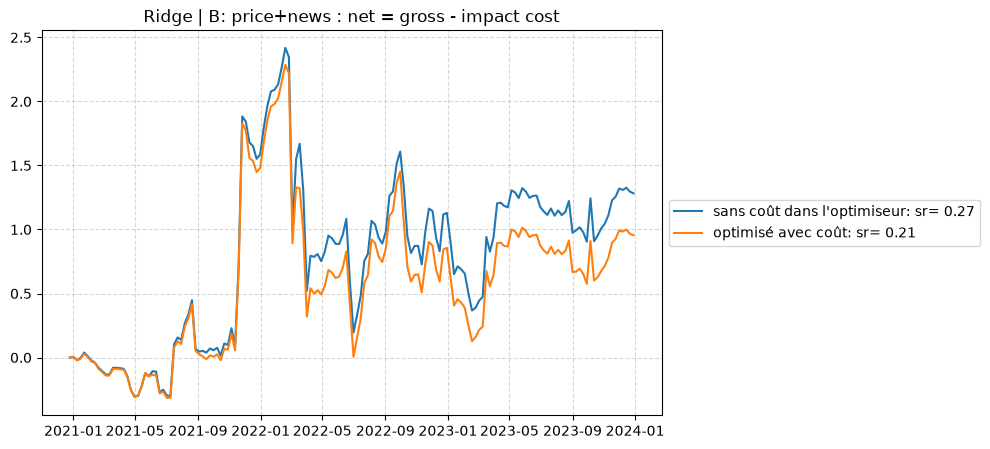

In [37]:
net_label = "net = gross - impact cost"

line(
    {"sans coût dans l'optimiseur": pnlc[net_label],
     "optimisé avec coût": m.pnl_[net_label]},
    cumsum=True,
    title=f"{KEY[0]} | {KEY[1]} : {net_label}",
)

In [38]:
print(
    f"Durée de détention moyenne (semaines) :"
    f"\n - sans coût dans l'optimiseur = {average_holding_period(m0.h_):.1f},"
    f"\n - optimisé avec coût quadratique = {average_holding_period(m.h_):.1f}."
)

Durée de détention moyenne (semaines) :
 - sans coût dans l'optimiseur = 2.0,
 - optimisé avec coût quadratique = 2.1.


## Comparaison des six jeux de prévisions

Mêmes contraintes, même modèle de risque, mêmes fenêtres : les écarts ne
viennent que des prévisions et de la prise en compte du coût.

In [39]:
rows, H = [], {}

for key, alpha in ALPHA_FULL.items():

    bt0 = BacktesterWithCost(
        MeanVarianceWithCost(), vol_liquidity_factor=None, **BT_KW
    ).train(alpha, TARGET_FULL, RET_REAL)

    bt1 = BacktesterWithCost(
        MeanVarianceWithCost(), vol_liquidity_factor,
        return_pnl_component=True, **BT_KW
    ).train(alpha, TARGET_FULL, RET_REAL)

    p0 = compute_pnl_components(bt0.h_, RET_REAL,
                                vol_liquidity_factor=vol_liquidity_factor)
    p1 = bt1.pnl_

    H[(key, "statique")] = bt0.h_
    H[(key, "dynamique")] = bt1.h_

    for label, p, h in [("statique", p0, bt0.h_), ("dynamique", p1, bt1.h_)]:
        rows.append({
            "modèle": key[0],
            "variables": key[1],
            "optimiseur": label,
            "sr brut": sharpe_ratio(p["gross"],num_period_per_year=52),
            "sr net": sharpe_ratio(p[net_label],num_period_per_year=52),
            "détention": average_holding_period(h),
        })

portfolio_results = (pd.DataFrame(rows)
                       .set_index(["modèle", "variables", "optimiseur"])
                       .sort_index())

display(portfolio_results.round(3))

sr brut  sr net  détention
modèle        variables     optimiseur                            
LightGBM      A: price      dynamique     0.236   0.119      2.348
                            statique      0.262   0.110      2.136
              B: price+news dynamique     0.335   0.236      2.452
                            statique      0.374   0.245      2.229
Random Forest A: price      dynamique     0.415   0.363      2.764
                            statique      0.457   0.391      2.497
              B: price+news dynamique     0.399   0.350      2.879
                            statique      0.448   0.386      2.596
Ridge         A: price      dynamique     0.497   0.434      2.213
                            statique      0.589   0.510      2.027
              B: price+news dynamique     0.257   0.209      2.130
                            statique      0.329   0.268      1.973

In [40]:
# Apport de l'optimisation dynamique, à prévisions identiques

w = portfolio_results.reset_index().pivot_table(
    index=["modèle", "variables"], columns="optimiseur",
    values=["sr net", "détention"])

gain_dyn = pd.DataFrame({
    "sr net statique": w[("sr net", "statique")],
    "sr net dynamique": w[("sr net", "dynamique")],
    "écart": w[("sr net", "dynamique")] - w[("sr net", "statique")],
    "détention statique": w[("détention", "statique")],
    "détention dynamique": w[("détention", "dynamique")],
})

display(gain_dyn.round(3))

sr net statique  sr net dynamique  écart  \
modèle        variables                                                 
LightGBM      A: price                 0.110             0.119  0.010   
              B: price+news            0.245             0.236 -0.010   
Random Forest A: price                 0.391             0.363 -0.028   
              B: price+news            0.386             0.350 -0.036   
Ridge         A: price                 0.510             0.434 -0.075   
              B: price+news            0.268             0.209 -0.059   

                             détention statique  détention dynamique  
modèle        variables                                               
LightGBM      A: price                    2.136                2.348  
              B: price+news               2.229                2.452  
Random Forest A: price                    2.497                2.764  
              B: price+news               2.596                2.879  
Ridge         A: price                    2.027                2.213  
              B: price+news               1.973                2.130

## Sensibilité au niveau de coût

L'hypothèse à tester : l'écart entre optimiseur dynamique et optimiseur
statique **s'élargit quand le coût augmente**, et s'annule quand le coût tend
vers zéro. Ce dernier point sert de contrôle — à coût nul les deux solutions
doivent coïncider.

In [41]:
SCALES = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]

rows = []

for s in SCALES:

    vlf_s = vol_liquidity_factor * s

    if s == 0:
        h_dyn = m0.h_
        p_dyn = compute_pnl_components(m0.h_, RET_REAL)
        sr_dyn = sharpe_ratio(p_dyn,num_period_per_year=52)
        hp_dyn = average_holding_period(m0.h_)
        sr_stat = sr_dyn
        hp_stat = hp_dyn
    else:
        bt = BacktesterWithCost(
            MeanVarianceWithCost(), vlf_s, return_pnl_component=True, **BT_KW
        ).train(ALPHA_FULL[KEY], TARGET_FULL, RET_REAL)

        p_stat = compute_pnl_components(m0.h_, RET_REAL,
                                        vol_liquidity_factor=vlf_s)
        sr_stat = sharpe_ratio(p_stat[net_label],num_period_per_year=52)
        hp_stat = average_holding_period(m0.h_)

        sr_dyn = sharpe_ratio(bt.pnl_[net_label],num_period_per_year=52)
        hp_dyn = average_holding_period(bt.h_)

    rows.append({"coût": s, "sr net statique": sr_stat,
                 "sr net dynamique": sr_dyn,
                 "détention statique": hp_stat,
                 "détention dynamique": hp_dyn})

sensi = pd.DataFrame(rows).set_index("coût")
display(sensi.round(3))

,sr net statique,sr net dynamique,détention statique,détention dynamique
coût,,,,
0.00,0.329,0.329,1.973,1.973
0.25,0.314,0.292,1.973,2.015
0.50,0.299,0.260,1.973,2.054
1.00,0.268,0.209,1.973,2.130
2.00,0.208,0.143,1.973,2.276
4.00,0.090,0.083,1.973,2.542


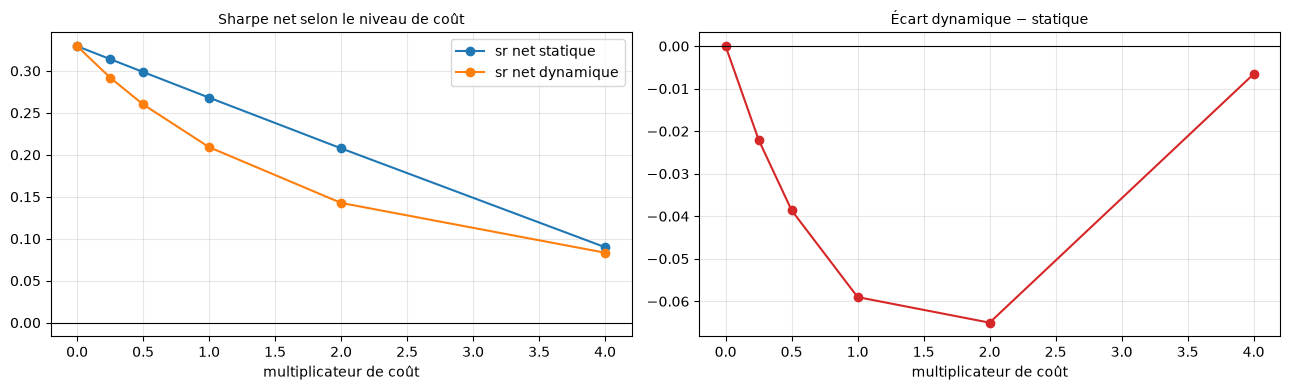

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sensi[["sr net statique", "sr net dynamique"]].plot(ax=ax[0], marker="o")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_title("Sharpe net selon le niveau de coût", fontsize=10)
ax[0].set_xlabel("multiplicateur de coût")
ax[0].grid(alpha=0.3)

(sensi["sr net dynamique"] - sensi["sr net statique"]).plot(
    ax=ax[1], marker="o", color="C3")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Écart dynamique − statique", fontsize=10)
ax[1].set_xlabel("multiplicateur de coût")
ax[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Détention et liquidité

Plus une matière première est chère à négocier, plus l'optimiseur devrait
allonger sa détention. Même graphique que le cours, au niveau des matières
premières.

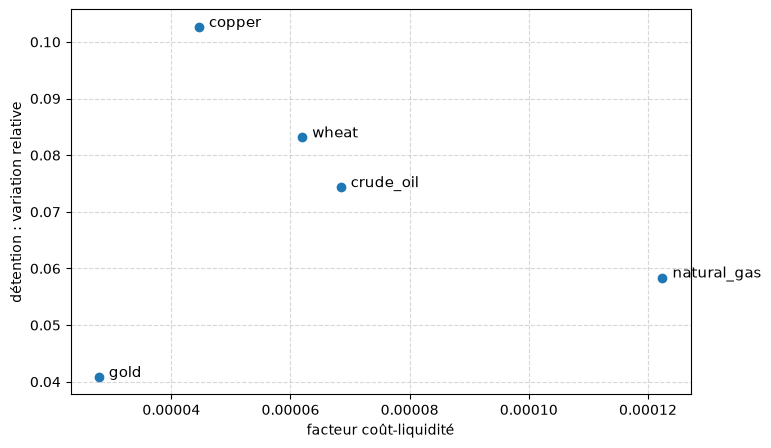

In [43]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.set_axisbelow(True)
ax.grid(True, linestyle="--", alpha=0.5)

avp = (
    pd.Series({col: average_holding_period(m.h_[col]) for col in m0.h_.columns})
    .div(pd.Series({col: average_holding_period(m0.h_[col]) for col in m0.h_.columns}))
    .sub(1)
)

scatter_df = pd.concat(
    {
        "facteur coût-liquidité": vol_liquidity_factor.loc[m0.h_.index[0]:].mean(),
        "détention : variation relative": avp,
    },
    axis=1,
)

ax.scatter(scatter_df.iloc[:, 0].values, scatter_df.iloc[:, 1].values)
ax.set_xlabel(scatter_df.columns[0])
ax.set_ylabel(scatter_df.columns[1])

for i, txt in enumerate(scatter_df.index):
    ax.text(scatter_df.iloc[i, 0], scatter_df.iloc[i, 1], "  " + txt, fontsize=11)

plt.show()

Cette cellule compare les positions produites par les deux optimiseurs, sur deux matières premières choisies comme exemples.

Pour chacune, elle empile les deux séries côte à côte — m0.h_[com] pour l’optimiseur statique, m.h_[com] pour le dynamique — et les trace sur le même axe, avec leur corrélation dans le titre.

Ce qu’elle doit montrer : la courbe dynamique devrait être une version lissée (la position bouge moins d’une semaine à l’autre.) de la statique.

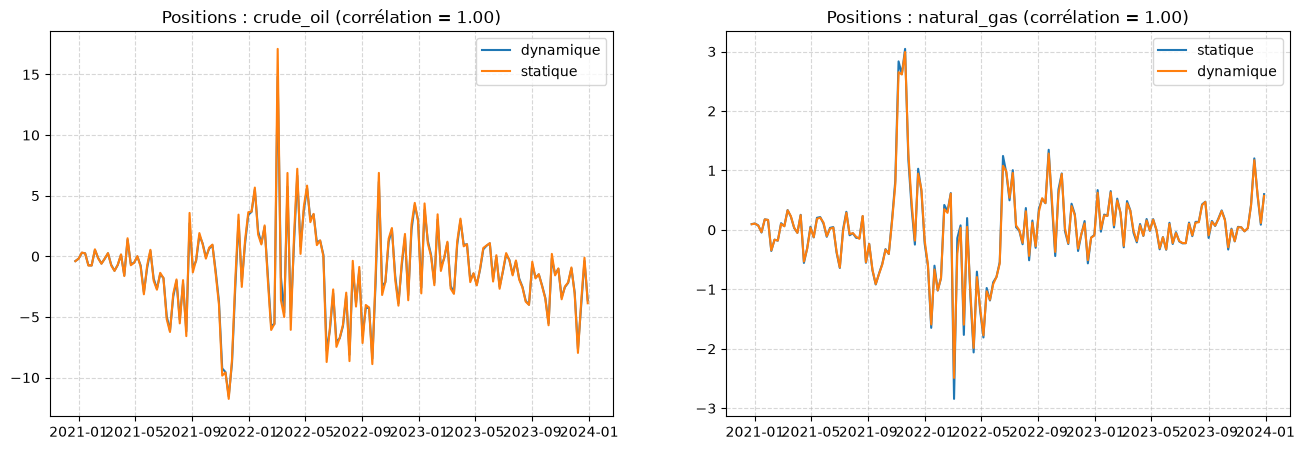

In [44]:
sample = ["crude_oil", "natural_gas"]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

for i, com in enumerate(sample):
    holdings_df = pd.concat(
        {"statique": m0.h_[com], "dynamique": m.h_[com]}, axis=1
    )
    line(
        holdings_df,
        title=f"Positions : {com} (corrélation ={holdings_df.corr().iloc[0, 1]: .2f})",
        ax=ax[i],
        loc="best",
    )

## Hypothèses

- Coût quadratique ($\beta = 1$), plus conservateur que la loi en racine carrée
  documentée par Frazzini, Israel et Moskowitz (2018), mais qui donne une
  solution fermée.
- Facteur de liquidité approché par la volatilité seule, à défaut de volumes.
- Covariance estimée sur 52 semaines glissantes, sans rétrécissement ni
  nettoyage des valeurs propres.
- Les modèles de prévision sont estimés une fois sur le train et ne sont pas
  ré-estimés à chaque fenêtre. Les six jeux de prévisions étant traités à
  l'identique, la comparaison des optimiseurs reste valide.
- Les prévisions antérieures à 2021 présentes dans `ALPHA_FULL` sont in-sample
  et ne servent qu'à amorcer les fenêtres du backtester ; aucune position n'est
  prise avant `start_date`.
- Tous les résultats portent sur la validation. L'échantillon de test reste
  fermé jusqu'à ce que le choix de l'optimiseur soit figé.